# 📈 Forecasting Weekly Product Demand — Part 2: Weekly Demand and EDA

**Goal of this notebook:** turn the clean transactions from Part 1 into **weekly demand per product**, choose which products to forecast, and explore the patterns a forecasting model has to learn: trend, yearly seasonality, intermittent (on/off) demand and outliers.

**Input:** `clean_sales.parquet` and `product_names.csv` from Part 1.
**Output:** `weekly_demand.parquet`, a complete product × week table ready for modelling.

## 1. Import Libraries and Load the Clean Data

In [125]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "data" / "processed"

sales = pd.read_parquet(PROCESSED_DIR / "clean_sales.parquet")
names = pd.read_csv(PROCESSED_DIR / "product_names.csv", dtype={"StockCode": "string"})

print(f"Sales rows : {len(sales):,}")
print(f"Products   : {sales['StockCode'].nunique():,}")
print(f"Date range : {sales['InvoiceDate'].min()} to {sales['InvoiceDate'].max()}")

Sales rows : 997,033
Products   : 4,700
Date range : 2009-12-01 07:45:00 to 2011-12-09 12:50:00


## 2. When Does the Shop Trade?

Before grouping sales into weeks, we need to know which days the shop actually sells on. If some days never have sales, a "week" with fewer days is not a problem, but a week that is cut off at the start or end of the data **is**.
### 2.1 — Trading days and units by day of week

In [126]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dates = sales["InvoiceDate"].dt.normalize()

by_day = pd.DataFrame({
    "trading_days": dates.drop_duplicates().dt.day_name().value_counts(),
    "units": sales.groupby(sales["InvoiceDate"].dt.day_name())["Quantity"].sum(),
}).reindex(day_order).fillna(0).astype(int)

by_day

,trading_days,units
InvoiceDate,,
Monday,94,1915375
Tuesday,104,2037438
Wednesday,104,1980147
Thursday,103,2265564
Friday,99,1567441
Saturday,1,4845
Sunday,99,1011747


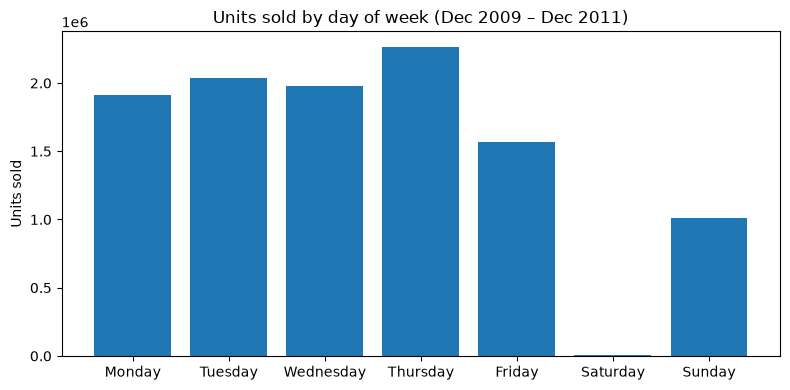

In [127]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_day.index, by_day["units"], color="tab:blue")
ax.set_ylabel("Units sold")
ax.set_title("Units sold by day of week (Dec 2009 – Dec 2011)")
plt.tight_layout()
plt.show()

📌 **Reading this:**
- The shop trades **Sunday to Friday**. Saturday had sales on only 1 day in two years, so the shop is effectively closed on Saturdays.
- Thursday is the busiest day and Sunday the quietest of the trading days.
- There are only **94 trading Mondays** compared with 104 Tuesdays and Wednesdays. Most UK bank holidays fall on a Monday, so the missing Mondays are holidays. That is a first sign that **holidays reduce weekly demand**, and we'll use them as a feature later.

### 2.2 — Where does the data start and end?

In [128]:
first, last = sales["InvoiceDate"].min(), sales["InvoiceDate"].max()
print(f"First sale: {first:%A %d %b %Y %H:%M}")
print(f"Last sale : {last:%A %d %b %Y %H:%M}")

First sale: Tuesday 01 Dec 2009 07:45
Last sale : Friday 09 Dec 2011 12:50


📌 **Reading this:** We'll use weeks that run from **Monday to Sunday**. The data starts on a Tuesday, so the first week is missing its Monday. It ends at 12:50 on a Friday, so the last week is missing most of Friday and all of Sunday. Both edge weeks would show artificially low demand, so we drop them.

## 3. Build Weekly Demand

### 3.1 — Assign every sale to a week

Each sale gets the date of the **Monday** that starts its week. Then we can add up units per week.

In [129]:
# W-SUN = weeks ending on Sunday, so each week starts on Monday
sales["week"] = sales["InvoiceDate"].dt.to_period("W-SUN").dt.start_time

first_week, last_week = sales["week"].min(), sales["week"].max()
print(f"First week starts: {first_week:%a %d %b %Y}")
print(f"Last week starts : {last_week:%a %d %b %Y}")
print(f"Number of weeks  : {sales['week'].nunique()}")

First week starts: Mon 30 Nov 2009
Last week starts : Mon 05 Dec 2011
Number of weeks  : 104


📌 **Reading this:** The data spans 106 calendar weeks (30 Nov 2009 to 5 Dec 2011), but only **104 weeks have any sales**. So two whole weeks have no sales at all; we check which ones in 3.4.

### 3.2 — Total units per week (all products)

The first chart of the actual demand we want to forecast. The two edge weeks are marked in red.

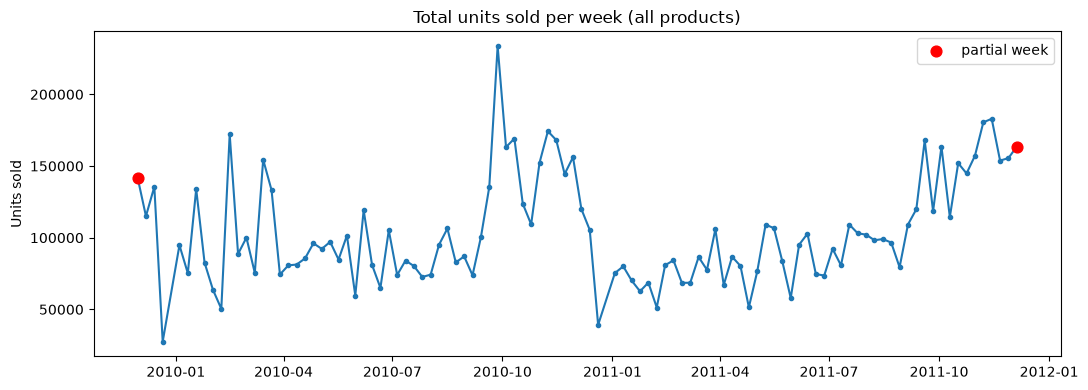

In [130]:
weekly_total = sales.groupby("week")["Quantity"].sum()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(weekly_total.index, weekly_total.values, marker=".", color="tab:blue")
ax.scatter([first_week, last_week], weekly_total.loc[[first_week, last_week]],
           color="red", s=60, zorder=3, label="partial week")
ax.set_ylabel("Units sold")
ax.set_title("Total units sold per week (all products)")
ax.legend()
plt.tight_layout()
plt.show()

📌 **Reading this:**
- Weekly demand is usually between about **75,000 and 110,000 units**, with a clear rise every **September to November** (gift season) in both years.
- Demand falls sharply around **Christmas and New Year** each year, when the shop is closed or nearly closed.
- There are a few sharp one-week spikes (the largest, about 235,000 units, is in autumn 2010). These are likely driven by large wholesale orders, which we check later.
- Autumn 2011 is slightly higher than autumn 2010, so there may be a small upward **trend**, but with only two years it's hard to be sure.
- The two red edge weeks don't look low here, because they fall in the busy pre-Christmas period. They still cover fewer trading days than a full week, so their totals can't be compared fairly with other weeks, and we drop them.

### 3.3 — Drop the two partial weeks

In [131]:
before_weeks = sales["week"].nunique()
sales = sales[(sales["week"] > first_week) & (sales["week"] < last_week)]

print(f"Weeks kept : {sales['week'].nunique()} (dropped {before_weeks - sales['week'].nunique()})")
print(f"Kept range : {sales['week'].min():%d %b %Y} to {sales['week'].max():%d %b %Y}")

Weeks kept : 102 (dropped 2)
Kept range : 07 Dec 2009 to 28 Nov 2011


📌 **Reading this:** After dropping the two partial edge weeks, 102 weeks with sales remain, from 7 Dec 2009 to 28 Nov 2011. That range covers 104 calendar weeks, so the two empty weeks are still inside it.

### 3.4 — Weeks with no sales at all

A forecasting model needs **every** week in order, with no gaps. If a week is simply missing, "last week's sales" would silently point to two weeks ago. Which weeks are missing?

In [132]:
all_weeks = pd.date_range(sales["week"].min(), sales["week"].max(), freq="W-MON")
missing_weeks = all_weeks.difference(sales["week"].unique())

print(f"Calendar weeks in range : {len(all_weeks)}")
print(f"Weeks with sales        : {sales['week'].nunique()}")
print("Weeks with no sales     :", [f"{w:%a %d %b %Y}" for w in missing_weeks])

Calendar weeks in range : 104
Weeks with sales        : 102
Weeks with no sales     : ['Mon 28 Dec 2009', 'Mon 27 Dec 2010']


📌 **Reading this:** The two empty weeks are **28 Dec 2009** and **27 Dec 2010**, the weeks between Christmas and New Year, when the shop was closed. These are real zero-demand weeks, not missing data. We'll put them back with **0 units** when we build the full product × week table, so every product has an unbroken run of 104 weeks.

## 4. Choose the Products to Forecast

There are 4,700 products, but most of them sell rarely. A forecast matters most for products that make up a large share of sales and have enough history to learn from. First we summarise every product, then we decide.

### 4.1 — Weekly units per product

In [133]:
prod_week = sales.groupby(["StockCode", "week"], as_index=False)["Quantity"].sum()
n_weeks = len(all_weeks)

summary = (
    prod_week.groupby("StockCode")
    .agg(total_units=("Quantity", "sum"),
         weeks_with_sales=("week", "nunique"),
         first_week=("week", "min"),
         last_week=("week", "max"))
    .sort_values("total_units", ascending=False)
)
summary["share_of_weeks"] = (summary["weeks_with_sales"] / n_weeks).round(2)
summary = summary.join(names.set_index("StockCode"))

print(f"Product-week rows with sales: {len(prod_week):,}")
summary.head(10)

Product-week rows with sales: 191,032


,total_units,weeks_with_sales,first_week,last_week,share_of_weeks,Description
StockCode,,,,,,
84077,103855,101,2009-12-07,2011-11-28,0.97,WORLD WAR 2 GLIDERS ASSTD DESIGNS
85099B,94720,102,2009-12-07,2011-11-28,0.98,JUMBO BAG RED RETROSPOT
21212,92338,102,2009-12-07,2011-11-28,0.98,PACK OF 72 RETROSPOT CAKE CASES
85123A,88865,102,2009-12-07,2011-11-28,0.98,WHITE HANGING HEART T-LIGHT HOLDER
22197,83132,102,2009-12-07,2011-11-28,0.98,SMALL POPCORN HOLDER
84879,76937,102,2009-12-07,2011-11-28,0.98,ASSORTED COLOUR BIRD ORNAMENT
17003,69173,96,2009-12-07,2011-11-28,0.92,BROCADE RING PURSE
21977,55173,102,2009-12-07,2011-11-28,0.98,PACK OF 60 PINK PAISLEY CAKE CASES
84991,53061,102,2009-12-07,2011-11-28,0.98,60 TEATIME FAIRY CAKE CASES


📌 **Reading this:** The best-selling products are everyday party and gift items (cake cases, jumbo bags, T-light holders) that sell in almost every week (97-98% of weeks). Most of the top 10 were on sale for the whole period, from Dec 2009 to Nov 2011.

### 4.2 — How concentrated are sales? (Pareto curve)

What share of all units comes from the top 50, 100, 200 and 500 products?

Top  50 products =  19.2% of all units sold
Top 100 products =  28.3% of all units sold
Top 200 products =  40.9% of all units sold
Top 500 products =  61.7% of all units sold


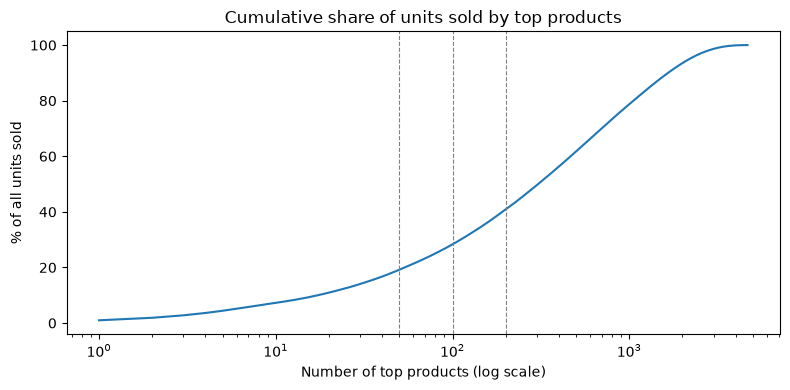

In [134]:
cum_share = summary["total_units"].cumsum() / summary["total_units"].sum()

for n in [50, 100, 200, 500]:
    print(f"Top {n:>3} products = {cum_share.iloc[n - 1] * 100:5.1f}% of all units sold")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(cum_share) + 1), cum_share.values * 100, color="tab:blue")
for n in [50, 100, 200]:
    ax.axvline(n, color="grey", linestyle="--", linewidth=0.8)
ax.set_xscale("log")
ax.set_xlabel("Number of top products (log scale)")
ax.set_ylabel("% of all units sold")
ax.set_title("Cumulative share of units sold by top products")
plt.tight_layout()
plt.show()

📌 **Reading this:** Sales are **spread across many products**. The top 100 make up only 28.3% of units, and it takes about 500 products to reach 60%. This is typical for a gift shop with thousands of small items. Forecasting every product would mostly mean forecasting noise, so we focus on the top products, which matter most for stock planning.

### 4.3 — Do the top 100 products have enough history?

A product that only started selling recently, or stopped selling, gives the model little to learn from. We check how many weeks each top-100 product actually sold in, and whether it was on sale for the whole period.

Sold in at least 90% of weeks: 69
Sold in at least 75% of weeks: 85
Sold in at least 50% of weeks: 94

Started selling after the first 8 weeks: 15
Stopped selling before the last 8 weeks: 2


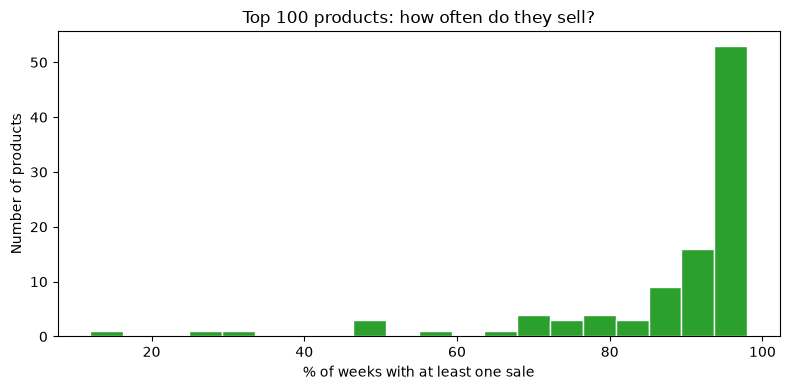

In [135]:
top100 = summary.head(100)

for t in [0.90, 0.75, 0.50]:
    print(f"Sold in at least {t:.0%} of weeks: {(top100['share_of_weeks'] >= t).sum()}")

starts_late = top100["first_week"] > all_weeks[7]    # first sale after week 8
ends_early = top100["last_week"] < all_weeks[-8]     # no sale in the last 8 weeks
print(f"\nStarted selling after the first 8 weeks: {starts_late.sum()}")
print(f"Stopped selling before the last 8 weeks: {ends_early.sum()}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(top100["share_of_weeks"] * 100, bins=20, color="tab:green", edgecolor="white")
ax.set_xlabel("% of weeks with at least one sale")
ax.set_ylabel("Number of products")
ax.set_title("Top 100 products: how often do they sell?")
plt.tight_layout()
plt.show()

In [136]:
# top-100 products with short history (new or discontinued)
top100.loc[starts_late | ends_early,
           ["Description", "total_units", "weeks_with_sales", "first_week", "last_week"]]

,Description,total_units,weeks_with_sales,first_week,last_week
StockCode,,,,,
22492,MINI PAINT SET VINTAGE,43097,82,2010-05-03,2011-11-28
22616,PACK OF 12 LONDON TISSUES,38522,82,2010-05-03,2011-11-28
21915,RED HARMONICA IN BOX,35410,89,2010-03-15,2011-11-28
22952,60 CAKE CASES VINTAGE CHRISTMAS,31907,50,2010-09-13,2011-11-28
22469,HEART OF WICKER SMALL,27679,77,2010-04-19,2011-11-28
23084,RABBIT NIGHT LIGHT,27506,30,2011-05-09,2011-11-28
37410,BLACK AND WHITE PAISLEY FLOWER MUG,25484,12,2009-12-07,2010-04-05
22423,REGENCY CAKESTAND 3 TIER,25379,89,2010-03-15,2011-11-28
84270,ASSTD DESIGN BUBBLE GUM RING,20532,50,2009-12-07,2010-12-06


📌 **Reading this:**
- Most top-100 products sell regularly: **69** sold in at least 90% of weeks, and **94** in at least half of them.
- **15** products only started selling later (for example *Rabbit Night Light*, first sold in May 2011, and *60 Cake Cases Vintage Christmas*, first sold in Sep 2010).
- **2** products stopped selling early. *Black and White Paisley Flower Mug* sold in only 12 weeks, and most of its total comes from one 19,152-unit wholesale order.
- A model that uses "same week last year" needs at least a full year of history, and our backtest needs more than that. So we only forecast products that were on sale for the **whole period**. Forecasting brand-new products (the "cold start" problem) is out of scope and listed as a limitation.

### 4.4 — Select the products

**Rule:** keep products that started selling in the first 8 weeks **and** were still selling in the last 8 weeks, then take the **top 100 by total units**.

In [137]:
TOP_N = 100

full_history = (summary["first_week"] <= all_weeks[7]) & (summary["last_week"] >= all_weeks[-8])
eligible = summary[full_history]
selected = eligible.head(TOP_N)

share = selected["total_units"].sum() / summary["total_units"].sum()
overlap = selected.index.isin(top100.index).sum()

print(f"Products with full history : {len(eligible):,}")
print(f"Selected                   : {len(selected)}")
print(f"Share of all units covered : {share:.1%}")
print(f"Also in the original top 100: {overlap}")
print(f"Lowest-selling selected product: {selected['total_units'].min():,} units")
print(f"Min share of weeks with sales  : {selected['share_of_weeks'].min():.0%}")

Products with full history : 1,777
Selected                   : 100
Share of all units covered : 26.8%
Also in the original top 100: 83
Lowest-selling selected product: 14,477 units
Min share of weeks with sales  : 56%


📌 **Reading this:** 1,777 products were on sale for the whole period. The top 100 of them cover **26.8% of all units**, and 83 of them were already in the overall top 100. The other 17 replace the new or discontinued products. Even the 100th product sold 14,477 units, and every selected product sold in at least 56% of weeks, so each one has enough history to learn from.

📌 **Why only 100 products, and not all 4,700:**
- **Most products sell too rarely.** A product that sells in only a handful of weeks gives a model almost nothing to learn; its "forecast" would mostly be noise.
- **The model needs full history.** We use "same week last year" as a feature and test the model on several past periods, so each product needs about two years of sales. Only 1,777 products have that.
- **These products matter most for stock.** Running out of a best-seller costs far more than running out of a rarely sold item, so businesses usually forecast their top sellers first (the "A" items in ABC analysis).
- **It keeps the project practical.** 100 products × 104 weeks trains and backtests quickly, and keeps the data the API needs small enough for a free hosting tier.

**100 is a choice, not a hard limit:** it is set by `TOP_N`, and the same pipeline can be re-run for more products by changing that one number.

### 4.5 — Build the complete product × week table

Every selected product gets **all 104 weeks**. Weeks with no sales (including the two Christmas closure weeks) get **0 units**. This gives the model an unbroken weekly series for each product.

In [138]:
grid = pd.MultiIndex.from_product(
    [selected.index, all_weeks], names=["StockCode", "week"]
).to_frame(index=False)

weekly = grid.merge(prod_week, on=["StockCode", "week"], how="left")
weekly["Quantity"] = weekly["Quantity"].fillna(0).astype(int)
weekly = weekly.rename(columns={"Quantity": "units"})

print(f"Rows: {len(weekly):,}  (= {weekly['StockCode'].nunique()} products x {weekly['week'].nunique()} weeks)")
print(f"Weeks with zero units: {(weekly['units'] == 0).mean():.1%}")
weekly.head()

Rows: 10,400  (= 100 products x 104 weeks)
Weeks with zero units: 6.4%


,StockCode,week,units
0,84077,2009-12-07,1204
1,84077,2009-12-14,720
2,84077,2009-12-21,48
3,84077,2009-12-28,0
4,84077,2010-01-04,336


📌 **Reading this:** The table has exactly **10,400 rows (100 products × 104 weeks)**, with no gaps. Only **6.4%** of product-weeks have zero units, and these include the two Christmas closure weeks (for example, 28 Dec 2009 above). So most of these products sell nearly every week.

## 5. Exploratory Data Analysis (EDA)

From here on we only look at the **100 selected products**, because these are the series we will forecast. Each plot answers one question about patterns the model has to learn.

### 5.1 — How does total weekly demand move over time?

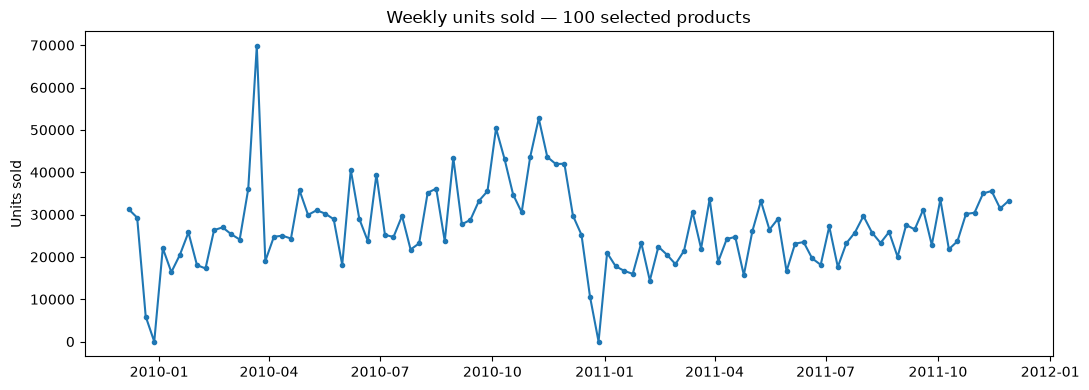

In [139]:
total = weekly.groupby("week")["units"].sum()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(total.index, total.values, marker=".", color="tab:blue")
ax.set_ylabel("Units sold")
ax.set_title("Weekly units sold — 100 selected products")
plt.tight_layout()
plt.show()

📌 **Reading this:**
- Weekly demand for the 100 products is usually between **20,000 and 35,000 units**, with a drop to near zero in each Christmas closure week.
- There is one isolated spike of about **70,000 units in March 2010**, much higher than any other week. That looks like a few very large orders rather than a real change in demand; we check large orders in 5.5.
- Autumn 2010 peaks at about 50,000 units, but **autumn 2011 only reaches about 35,000**. In Part 1 the shop as a whole sold slightly *more* in 2011, so the 2011 growth came from **newer products**, which we excluded. Our long-running products are slowly selling less (a normal product life cycle). A "same week last year" forecast may therefore come out a little too high.

### 5.2 — Is the yearly pattern the same in both years?

We plot 2010 and 2011 on top of each other by week of the year. If the two lines rise and fall together, the seasonality repeats, and a model can learn it from "the same week last year".

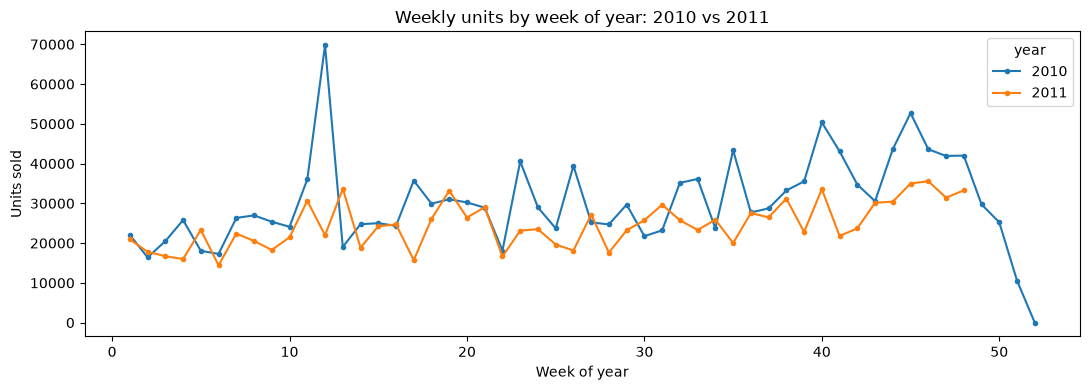

In [140]:
season = total.to_frame("units")
season["year"] = season.index.year
season["week_of_year"] = season.index.isocalendar().week.values

pivot = season[season["year"].isin([2010, 2011])].pivot_table(
    index="week_of_year", columns="year", values="units"
)

ax = pivot.plot(figsize=(11, 4), marker=".")
ax.set_xlabel("Week of year")
ax.set_ylabel("Units sold")
ax.set_title("Weekly units by week of year: 2010 vs 2011")
plt.tight_layout()
plt.show()

📌 **Reading this:** Both years rise towards **weeks 40–48 (October–November)**, so the gift-season pattern repeats and "same week last year" is a useful signal. But the match is far from perfect: 2010 has a sharper autumn peak and several one-week spikes (the biggest in week 12), while 2011 is flatter. Week-to-week noise is large compared with the seasonal pattern, so the model will need more than just last year's value: recent weeks' sales (lags and rolling averages) as well.

### 5.3 — What do individual products look like?

Totals hide a lot. Here are six products: the top 3 sellers and three from lower down the list (ranks 50, 75 and 100).

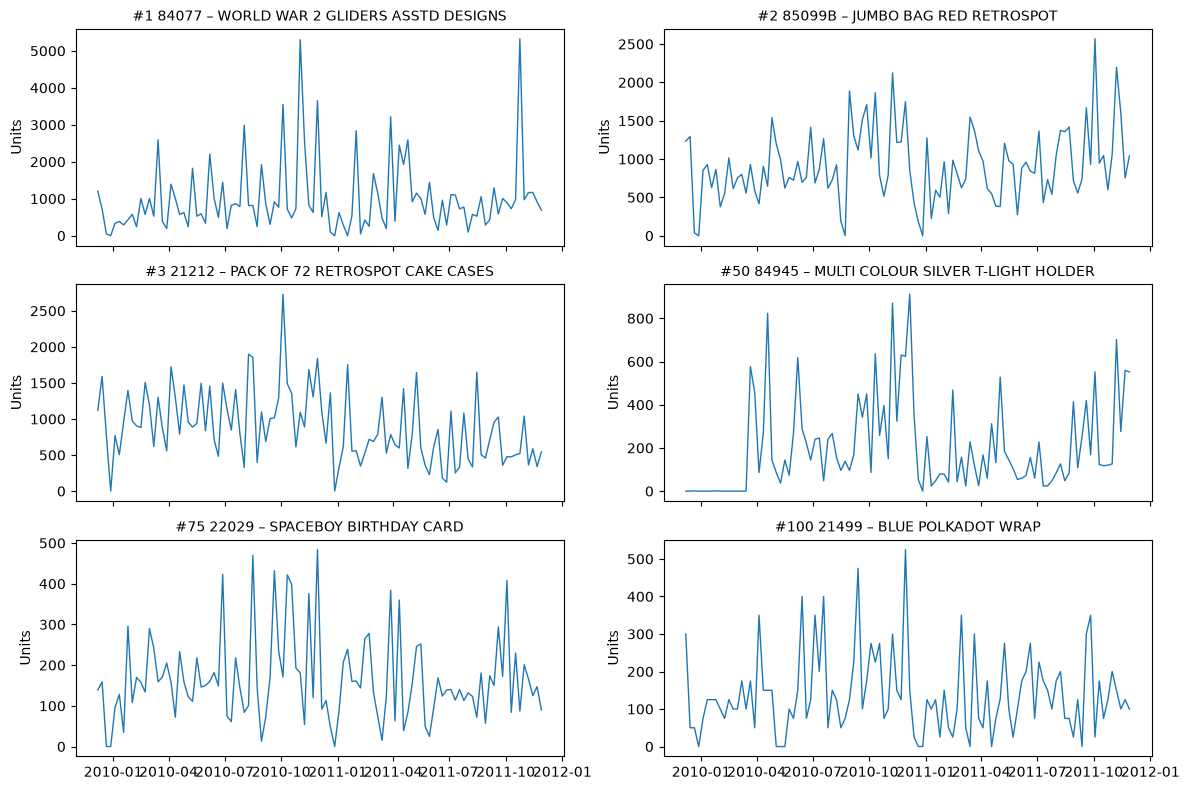

In [141]:
picks = selected.index[[0, 1, 2, 49, 74, 99]]

fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True)
for ax, code in zip(axes.flat, picks):
    s = weekly[weekly["StockCode"] == code]
    ax.plot(s["week"], s["units"], linewidth=1)
    rank = selected.index.get_loc(code) + 1
    ax.set_title(f"#{rank} {code} – {selected.loc[code, 'Description'][:35]}", fontsize=10)
    ax.set_ylabel("Units")
plt.tight_layout()
plt.show()

📌 **Reading this:**
- Individual products are **much noisier** than the total. For example, #1 (*World War 2 Gliders*) usually sells around 1,000 units a week, but a few weeks jump to 5,000+, which looks like one-off bulk orders.
- Most products sell in almost every week, with zeros mainly in the Christmas weeks.
- Some products have a slow start: #50 (*Multi Colour Silver T-Light Holder*) sold almost nothing for the first ~20 weeks and then took off. It passed our "full history" rule because it had a few small early sales.
- These one-off spikes are a risk: a model could learn them as normal demand. 5.5 measures how big this problem is.

### 5.4 — Smooth or intermittent demand? (ADI and CV²)

Demand patterns are often classified with two numbers (Syntetos-Boylan classification):
- **ADI (Average Demand Interval):** the average number of weeks between sales. 1.0 means a sale every week.
- **CV²:** how much the size of non-zero weekly sales varies (squared coefficient of variation).

Using the standard cut-offs (ADI = 1.32, CV² = 0.49), each product is **smooth**, **erratic** (sells often but amounts jump around), **intermittent** (often zero, steady amounts) or **lumpy** (often zero and jumpy). Intermittent and lumpy products usually need special methods such as Croston's.

In [142]:
def demand_stats(s):
    nonzero = s[s > 0]
    adi = len(s) / len(nonzero)
    cv2 = (nonzero.std() / nonzero.mean()) ** 2
    return pd.Series({"ADI": adi, "CV2": cv2})

def classify(row):
    if row["ADI"] < 1.32:
        return "smooth" if row["CV2"] < 0.49 else "erratic"
    return "intermittent" if row["CV2"] < 0.49 else "lumpy"

stats = weekly.groupby("StockCode")["units"].apply(demand_stats).unstack()
stats["pattern"] = stats.apply(classify, axis=1)

stats["pattern"].value_counts()

pattern
erratic    65
smooth     31
lumpy       4
Name: count, dtype: int64

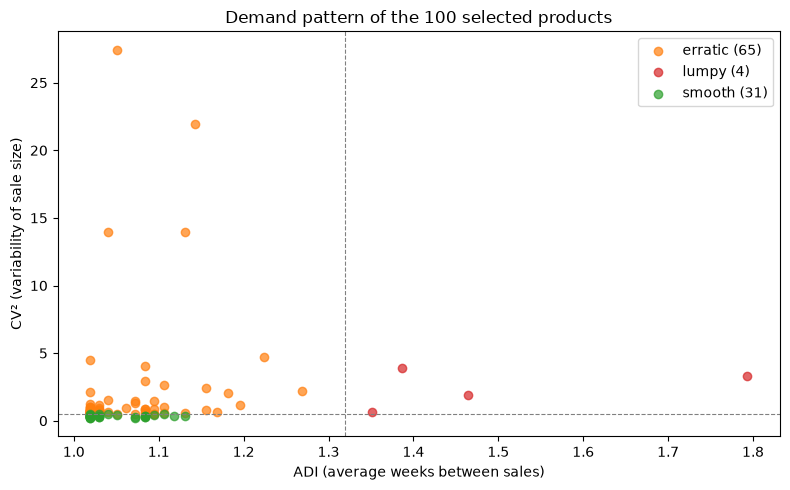

In [143]:
colors = {"smooth": "tab:green", "erratic": "tab:orange",
          "intermittent": "tab:blue", "lumpy": "tab:red"}

fig, ax = plt.subplots(figsize=(8, 5))
for p, g in stats.groupby("pattern"):
    ax.scatter(g["ADI"], g["CV2"], label=f"{p} ({len(g)})", color=colors[p], alpha=0.7)
ax.axvline(1.32, color="grey", linestyle="--", linewidth=0.8)
ax.axhline(0.49, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("ADI (average weeks between sales)")
ax.set_ylabel("CV² (variability of sale size)")
ax.set_title("Demand pattern of the 100 selected products")
ax.legend()
plt.tight_layout()
plt.show()

📌 **Reading this:**
- **65 products are erratic, 31 smooth, 4 lumpy and none intermittent.** Almost every product sells in nearly every week (ADI between 1.0 and 1.2), but the weekly amount varies a lot.
- Only 4 products (in red) have ADI above 1.32, so intermittent-demand methods like Croston's matter for very few series.
- Four erratic products sit far above the rest, with CV² between 14 and 27, while most products have CV² below 5. Such extreme variability usually means a product's sales are dominated by one or two huge orders. 5.5 confirms this.

### 5.5 — How much do one-off large orders distort demand?

Two checks: what share of these products' units comes from lines of 1,000+ units (`is_large_line` from Part 1), and how far each product's biggest week is above its typical (median) week.

In [144]:
sel_sales = sales[sales["StockCode"].isin(selected.index)]
large_share = (sel_sales.loc[sel_sales["is_large_line"], "Quantity"].sum()
               / sel_sales["Quantity"].sum())
print(f"Large lines (1,000+ units) in selected products: {sel_sales['is_large_line'].sum():,}")
print(f"Share of their units from large lines          : {large_share:.1%}\n")

spike = weekly.groupby("StockCode")["units"].agg(median="median", max="max")
spike["max_to_median"] = (spike["max"] / spike["median"]).round(1)
spike = spike.join(selected["Description"]).sort_values("max_to_median", ascending=False)

print(spike["max_to_median"].describe().round(1))
spike.head(10)

Large lines (1,000+ units) in selected products: 119
Share of their units from large lines          : 8.7%

count     100.0
mean       33.9
std       143.5
min         2.6
25%         4.2
50%         5.8
75%         9.1
max      1366.7
Name: max_to_median, dtype: float64


,median,max,max_to_median,Description
StockCode,,,,
16014,3.0,4100,1366.7,SMALL CHINESE STYLE SCISSOR
84347,9.0,3382,375.8,ROTATING SILVER ANGELS T-LIGHT HLDR
84598,15.5,2884,186.1,BOYS ALPHABET IRON ON PATCHES
21984,60.0,11109,185.2,PACK OF 12 PINK PAISLEY TISSUES
21981,73.5,10696,145.5,PACK OF 12 WOODLAND TISSUES
21982,92.5,11414,123.4,PACK OF 12 SUKI TISSUES
22086,18.5,2153,116.4,PAPER CHAIN KIT 50'S CHRISTMAS
21980,117.0,10070,86.1,PACK OF 12 RED RETROSPOT TISSUES
20668,24.0,1656,69.0,DISCO BALL CHRISTMAS DECORATION


📌 **Reading this:**
- Only 119 order lines of 1,000+ units account for **8.7%** of these products' units.
- For a typical product, the biggest week is about **6 times** its median week, which is normal peak-season variation.
- But a few products are extreme. *Small Chinese Style Scissor* normally sells **3 units a week** but once sold **4,100**. Four *Pack of 12 Tissues* products normally sell 60–120 a week but each had one week of **10,000–11,000 units**. These look like bulk orders in March 2010 and explain the 70,000-unit spike we saw in 5.1.
- **Problem:** we ranked products by total units, so some made the top 100 only because of one or two bulk orders. No model can predict a random one-off bulk order, so these are poor choices for a demand forecast.

### 5.6 — How many products depend on a single week?

If a large part of a product's two-year total comes from **one week**, its ranking is driven by a one-off event, not by regular demand.

In [145]:
g = weekly.groupby("StockCode")["units"]
spike["top_week_share"] = (g.max() / g.sum()).round(3)

for t in [0.10, 0.25, 0.50]:
    print(f"Products with more than {t:.0%} of all units in one week: {(spike['top_week_share'] > t).sum()}")

spike.sort_values("top_week_share", ascending=False).head(10)

Products with more than 10% of all units in one week: 12
Products with more than 25% of all units in one week: 4
Products with more than 50% of all units in one week: 1


,median,max,max_to_median,Description,top_week_share
StockCode,,,,,
21984,60.0,11109,185.2,PACK OF 12 PINK PAISLEY TISSUES,0.527
21981,73.5,10696,145.5,PACK OF 12 WOODLAND TISSUES,0.493
21980,117.0,10070,86.1,PACK OF 12 RED RETROSPOT TISSUES,0.375
21982,92.5,11414,123.4,PACK OF 12 SUKI TISSUES,0.357
21985,129.0,5007,38.8,PACK OF 12 HEARTS DESIGN TISSUES,0.199
84347,9.0,3382,375.8,ROTATING SILVER ANGELS T-LIGHT HLDR,0.172
17003,237.0,11174,47.1,BROCADE RING PURSE,0.162
84598,15.5,2884,186.1,BOYS ALPHABET IRON ON PATCHES,0.147
16014,3.0,4100,1366.7,SMALL CHINESE STYLE SCISSOR,0.140


📌 **Reading this:** 12 products got more than 10% of their two-year total in a single week, and 4 got more than 25%. The worst case, *Pack of 12 Pink Paisley Tissues*, sold **52.7%** of everything in one week. The five *Pack of 12 Tissues* products all appear here, so this is one bulk purchase spread over several designs. These products are in the top 100 because of one-off events, not regular demand, so we fix the selection in the next section.

## 6. Re-select Products Using Typical Demand

The EDA showed that ranking by raw total units rewards products with one-off bulk orders. We rank again, this time on demand with extreme weeks capped.

### 6.1 — Cap extreme weeks for ranking

For each product we compute an **outlier fence = Q3 + 3 × IQR** of its weekly units. The factor 3 (instead of the usual 1.5) means only *extreme* weeks are capped, while normal gift-season peaks are kept. Each week above the fence is set to the fence, and products are ranked on the capped total.

This capping is **only used for choosing products**. The `units` column itself is not changed here.

In [146]:
# weekly units for every product with full history (1,777 products x 104 weeks)
elig_weekly = (
    pd.MultiIndex.from_product([eligible.index, all_weeks], names=["StockCode", "week"])
    .to_frame(index=False)
    .merge(prod_week, on=["StockCode", "week"], how="left")
    .fillna({"Quantity": 0})
)

# outlier fence per product
q = elig_weekly.groupby("StockCode")["Quantity"].quantile([0.25, 0.75]).unstack()
fence = q[0.75] + 3 * (q[0.75] - q[0.25])

elig_weekly["capped"] = elig_weekly["Quantity"].clip(upper=elig_weekly["StockCode"].map(fence))
capped_total = elig_weekly.groupby("StockCode")["capped"].sum().sort_values(ascending=False)

removed_share = 1 - elig_weekly["capped"].sum() / elig_weekly["Quantity"].sum()
print(f"Share of units above the fence (all 1,777 products): {removed_share:.1%}")

Share of units above the fence (all 1,777 products): 12.1%


📌 **Reading this:** Across all 1,777 products with full history, **12.1%** of units fall in extreme weeks above the fence. That is a lot of demand coming from one-off events, which confirms that ranking on raw totals is risky.

### 6.2 — Which products change?

In [147]:
new_codes = capped_total.head(TOP_N).index
dropped = selected.index.difference(new_codes)
added = new_codes.difference(selected.index)

print(f"Dropped: {len(dropped)}   Added: {len(added)}\n")
print("Dropped products (raw total vs capped total):")
summary.loc[dropped, ["Description", "total_units"]].assign(
    capped_total=capped_total[dropped].round()
).sort_values("total_units", ascending=False)

Dropped: 5   Added: 5

Dropped products (raw total vs capped total):


,Description,total_units,capped_total
StockCode,,,
16014,SMALL CHINESE STYLE SCISSOR,29275,3779.0
21981,PACK OF 12 WOODLAND TISSUES,21703,10689.0
21984,PACK OF 12 PINK PAISLEY TISSUES,21091,8920.0
84598,BOYS ALPHABET IRON ON PATCHES,19587,6575.0
22189,CREAM HEART CARD HOLDER,15483,12423.0


📌 **Reading this:** Only **5 products** changed. The ones dropped are exactly the bulk-order cases: *Small Chinese Style Scissor* falls from 29,275 to 3,779 units once its extreme weeks are capped, and two *Pack of 12 Tissues* products lose about half their total. Five products with steadier demand take their place, so the selection is largely stable.

### 6.3 — Rebuild the weekly table and re-check

We rebuild the product × week table for the new selection and repeat the key checks from 5.4 and 5.6.

In [148]:
total_v1 = total.copy()   # weekly total of the first selection, for comparison

selected = eligible.loc[new_codes].assign(capped_total=capped_total[new_codes].round())

weekly = (
    pd.MultiIndex.from_product([selected.index, all_weeks], names=["StockCode", "week"])
    .to_frame(index=False)
    .merge(prod_week, on=["StockCode", "week"], how="left")
    .fillna({"Quantity": 0})
    .rename(columns={"Quantity": "units"})
)
weekly["units"] = weekly["units"].astype(int)

g = weekly.groupby("StockCode")["units"]
top_week_share = g.max() / g.sum()
stats = g.apply(demand_stats).unstack()
stats["pattern"] = stats.apply(classify, axis=1)

print(f"Rows: {len(weekly):,}")
print(f"Share of all units covered: {weekly['units'].sum() / summary['total_units'].sum():.1%}")
print(f"Products with >25% of units in one week: {(top_week_share > 0.25).sum()}")
print(f"Products with >10% of units in one week: {(top_week_share > 0.10).sum()}")
print(f"Max CV²: {stats['CV2'].max():.1f}\n")
print(stats["pattern"].value_counts())

Rows: 10,400
Share of all units covered: 26.5%
Products with >25% of units in one week: 2
Products with >10% of units in one week: 7
Max CV²: 14.0

pattern
erratic    66
smooth     31
lumpy       3
Name: count, dtype: int64


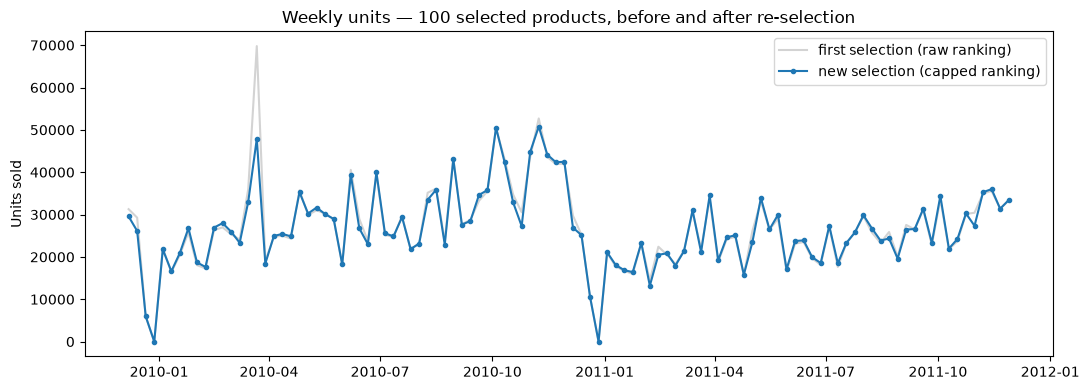

In [149]:
total = weekly.groupby("week")["units"].sum()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(total_v1.index, total_v1.values, color="lightgrey", label="first selection (raw ranking)")
ax.plot(total.index, total.values, color="tab:blue", marker=".", label="new selection (capped ranking)")
ax.set_ylabel("Units sold")
ax.set_title("Weekly units — 100 selected products, before and after re-selection")
ax.legend()
plt.tight_layout()
plt.show()

📌 **Reading this:**
- The new selection still covers **26.5%** of all units, almost the same as before.
- Products with more than 25% of their sales in one week fell from 4 to **2**, and the highest CV² fell from 27.4 to **14.0**. The March 2010 spike in the total drops from about 70,000 to about 48,000 units.
- Two *Pack of 12 Tissues* products remain. They still had one bulk week, but they also have solid regular demand (about 90–120 units a week), so we keep them. Their spikes will be capped when training the model and reported separately in the evaluation, rather than hidden by more hand-picking.

## 7. Which Past Weeks Help Predict Demand?

**Autocorrelation** measures how similar a product's sales are to its own sales L weeks earlier (1 = moves exactly together, 0 = unrelated). We compute it per product for several lags and plot the median across the 100 products. Lags with clear correlation are good candidates for model features.

1     0.20
2     0.14
3     0.10
4     0.09
8     0.06
13   -0.00
26   -0.03
52    0.15
dtype: float64


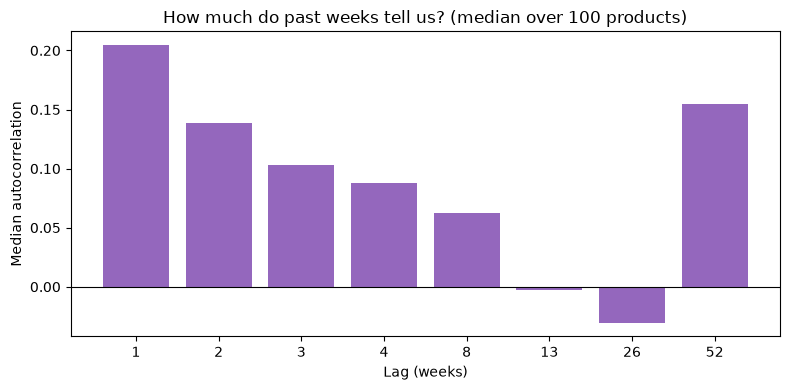

In [150]:
lags = [1, 2, 3, 4, 8, 13, 26, 52]
weekly = weekly.sort_values(["StockCode", "week"]).reset_index(drop=True)

acf = (
    weekly.groupby("StockCode")["units"]
    .apply(lambda s: pd.Series({L: s.autocorr(L) for L in lags}))
    .unstack()
)
median_acf = acf.median()
print(median_acf.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([str(L) for L in lags], median_acf.values, color="tab:purple")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Lag (weeks)")
ax.set_ylabel("Median autocorrelation")
ax.set_title("How much do past weeks tell us? (median over 100 products)")
plt.tight_layout()
plt.show()

📌 **Reading this:**
- **Last week (lag 1)** has the strongest link to this week's sales, with a median autocorrelation of 0.20. The link fades over lags 2–8 and is **about zero at 13–26 weeks**.
- **Lag 52 rises again to 0.15**: sales in the same week last year carry information. That confirms the yearly seasonality we saw in 5.2.
- **All values are small** (below 0.2), because weekly sales per product are noisy. A single past week is a weak predictor. **Averages over several weeks** (rolling means) should be more useful, since averaging cancels out much of the noise.
- **Feature plan:** lags 1–4, rolling means over 4, 8 and 13 weeks, lag 52, and the year-over-year ratio. We should also expect the model to beat simple baselines by a modest margin rather than a huge one, which is normal for noisy retail data.

## 8. Save the Weekly Demand Table

- `weekly_demand.parquet`: 100 products × 104 weeks, raw weekly units (no capping)
- `selected_products.csv`: the chosen products with their name, capped total and demand pattern

In [151]:
weekly.to_parquet(PROCESSED_DIR / "weekly_demand.parquet", index=False)

products = selected[["Description", "capped_total"]].join(stats[["ADI", "CV2", "pattern"]]).round(3)
products.to_csv(PROCESSED_DIR / "selected_products.csv")

for f in ["weekly_demand.parquet", "selected_products.csv"]:
    size_kb = (PROCESSED_DIR / f).stat().st_size / 1e3
    print(f"saved {f:24s} {size_kb:7.1f} KB")

saved weekly_demand.parquet       23.6 KB
saved selected_products.csv        6.2 KB


📌 **Reading this:** The final weekly table is small (23.6 KB). It is easy to load in the modelling notebooks, and later in the API.

## 9. Summary

**What we built**
- Weekly demand (Monday-to-Sunday weeks) for **100 products × 104 weeks** (7 Dec 2009 – 28 Nov 2011), with zero-sales weeks filled with 0. The two partial edge weeks were dropped.
- Products were chosen from the **1,777 with full two-year history**, ranked on demand with extreme weeks capped (Q3 + 3 × IQR), so that one-off bulk orders don't drive the selection. They cover **26.5%** of all units.

**What the EDA showed**
- **Trading days:** the shop trades Sunday–Friday. Fewer Mondays (bank holidays) and two Christmas closure weeks show that **holidays reduce demand**.
- **Seasonality:** demand peaks every **September–November**, and lag-52 autocorrelation confirms the pattern repeats yearly.
- **Level change:** our long-running products sold less in 2011 than in 2010 (growth came from newer products), so "same week last year" alone would over-forecast.
- **Demand pattern:** most products sell almost every week but in very variable amounts (66 erratic, 31 smooth, 3 lumpy, 0 intermittent).
- **Bulk orders:** large one-off orders make up a noticeable share of units. Two selected products still have one big bulk week.
- **Noise:** week-to-week autocorrelation is weak (≤ 0.2), so rolling averages should matter more than single lags.

**Decisions carried forward**
- Features: recent lags, rolling means, lag 52, a year-over-year ratio, calendar and UK holidays.
- Extreme weeks will be capped **in training only**, with the cap computed from training data, and the evaluation will report errors **with and without** bulk-order weeks.
- Limitations: only two seasonal cycles; new products (cold start) are not forecast; the top 100 is a choice (`TOP_N`) and can be extended.

**Next (Part 3):** time-based train/test split, simple baselines (seasonal naive, moving average) and the evaluation metrics.